#### Baselines - Random Forest and XGBoost

Horizons: 1h, 24h and 168h ahead (direct approach, one model per horizon).
Also a seasonal naive forecast (same hour last week) as a simple reference.

Same setup as the deep models in notebook 05, so the comparison is fair:
- tuned with Optuna on the validation set at h=24 only (8 trials), best settings reused for 1h and 168h
- PJME: trained on the last 4 years of the train period (~35k hours). val / test are the full periods
- final models trained with 3 seeds, scored on test
- predictions saved in results/ for the evaluation notebook

In [1]:
import os
import json
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score

optuna.logging.set_verbosity(optuna.logging.WARNING)

os.makedirs("../figures", exist_ok=True)

In [2]:
HORIZONS = [1, 24, 168]
SEEDS = [0, 1, 2]
N_TRIALS = 8
PJME_TRAIN_HOURS = 24 * 365 * 4

os.makedirs("../results/predictions", exist_ok=True)

##### Features

Index = the hour we are predicting (target time). For horizon h the forecast is made h hours before,
so every load feature has to be shifted by at least h.

- lag_h ... lag_h+5: last 6 known hours
- lag_24, 48, 168, 336: same hour 1/2 days and 1/2 weeks before (only the ones >= h)
- rolling mean of the last 24h / 168h known at forecast time
- calendar features of the target hour

In [3]:
def make_features(df, h):
    X = pd.DataFrame(index=df.index)

    lags = [h + k for k in range(6)] + [m for m in [24, 48, 168, 336] if m >= h]
    for s in sorted(set(lags)):
        X[f"lag_{s}"] = df["load"].shift(s)

    X["roll_mean_24"] = df["load"].shift(h).rolling(24).mean()
    X["roll_mean_168"] = df["load"].shift(h).rolling(168).mean()

    for c in ["hour", "dayofweek", "month", "dayofyear", "weekend", "holiday"]:
        X[c] = df[c]

    X = X.dropna()
    y = df["load"].loc[X.index]
    return X, y

In [4]:
def load_data(name):
    train = pd.read_parquet(f"../data/processed/{name}_train.parquet")
    val = pd.read_parquet(f"../data/processed/{name}_val.parquet")
    test = pd.read_parquet(f"../data/processed/{name}_test.parquet")
    return train, val, test


def get_splits(name, h):
    train, val, test = load_data(name)
    # features are made on the full series so the first val/test rows can use the last known values
    X, y = make_features(pd.concat([train, val, test]), h)
    tr = X.index <= train.index.max()
    if name == "pjme":
        # last 4 years of train only, same as the deep models
        tr = tr & (X.index >= train.index[-PJME_TRAIN_HOURS])
    va = (X.index >= val.index.min()) & (X.index <= val.index.max())
    te = X.index >= test.index.min()
    return X[tr], y[tr], X[va], y[va], X[te], y[te]


def scores(y, pred):
    return {
        "rmse": np.sqrt(mean_squared_error(y, pred)),
        "mae": mean_absolute_error(y, pred),
        "mape": mean_absolute_percentage_error(y, pred) * 100,
        "r2": r2_score(y, pred),
    }

In [5]:
X_tr, y_tr, X_va, y_va, X_te, y_te = get_splits("pjme", 24)
print(X_tr.shape, X_va.shape, X_te.shape)
X_tr.head()

(35040, 17) (21809, 17) (21809, 17)


,lag_24,lag_25,lag_26,lag_27,lag_28,lag_29,lag_48,lag_168,lag_336,roll_mean_24,roll_mean_168,hour,dayofweek,month,dayofyear,weekend,holiday
Datetime,,,,,,,,,,,,,,,,,
2009-08-12 15:00:00,51690.0,50959.0,49689.0,47963.0,45658.0,42953.0,54008.0,49014.0,46846.0,44172.083333,37014.154762,15,2,8,224,0,0
2009-08-12 16:00:00,52370.0,51690.0,50959.0,49689.0,47963.0,45658.0,54827.0,49127.0,46802.0,44069.708333,37034.351190,16,2,8,224,0,0
2009-08-12 17:00:00,52928.0,52370.0,51690.0,50959.0,49689.0,47963.0,55433.0,48809.0,46646.0,43965.333333,37055.595238,17,2,8,224,0,0
2009-08-12 18:00:00,52576.0,52928.0,52370.0,51690.0,50959.0,49689.0,55124.0,48271.0,45791.0,43859.166667,37075.809524,18,2,8,224,0,0
2009-08-12 19:00:00,50563.0,52576.0,52928.0,52370.0,51690.0,50959.0,53626.0,46760.0,44233.0,43731.541667,37093.273810,19,2,8,224,0,0


##### Tuning

In [6]:
def tune_rf(X_tr, y_tr, X_va, y_va):
    def objective(trial):
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 100, 400, step=50),
            "max_depth": trial.suggest_int("max_depth", 5, 30),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20),
            "max_features": trial.suggest_categorical("max_features", [0.3, 0.5, 0.8, 1.0]),
        }
        # max_samples=0.5 to keep it fast on the PJME data
        model = RandomForestRegressor(**params, max_samples=0.5, n_jobs=-1, random_state=0)
        model.fit(X_tr, y_tr)
        return np.sqrt(mean_squared_error(y_va, model.predict(X_va)))

    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=N_TRIALS)
    return study.best_params, study.best_value


def tune_xgb(X_tr, y_tr, X_va, y_va):
    def objective(trial):
        params = {
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            "max_depth": trial.suggest_int("max_depth", 3, 10),
            "min_child_weight": trial.suggest_int("min_child_weight", 1, 20),
            "subsample": trial.suggest_float("subsample", 0.5, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        }
        model = xgb.XGBRegressor(**params, n_estimators=2000, early_stopping_rounds=50,
                                 tree_method="hist", n_jobs=-1, random_state=0)
        model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
        trial.set_user_attr("n_estimators", model.best_iteration + 1)
        return np.sqrt(mean_squared_error(y_va, model.predict(X_va)))

    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=N_TRIALS)
    params = study.best_params
    params["n_estimators"] = study.best_trial.user_attrs["n_estimators"]
    return params, study.best_value

##### Run everything

Tuning once per dataset at h=24, then the final models for all horizons. About 10 min.

In [7]:
all_scores = []
best_params = {}
models_24 = {}

for name in ["pjme", "uci"]:
    # tune once at h=24 (same as the deep models), the settings are reused for 1h and 168h
    start = time.time()
    X_tr, y_tr, X_va, y_va, _, _ = get_splits(name, 24)
    rf_params, rf_val = tune_rf(X_tr, y_tr, X_va, y_va)
    xgb_params, xgb_val = tune_xgb(X_tr, y_tr, X_va, y_va)
    best_params[name] = {"rf": rf_params, "xgb": xgb_params}
    print(f"{name} tuning: val rmse rf={rf_val:.3f} xgb={xgb_val:.3f}  ({time.time() - start:.0f}s)")

    for h in HORIZONS:
        start = time.time()
        X_tr, y_tr, X_va, y_va, X_te, y_te = get_splits(name, h)
        preds = {}

        # seasonal naive - same hour one week before (known for all horizons up to 168)
        preds["naive"] = {"seed_0": X_te["lag_168"].values}

        preds["rf"], preds["xgb"] = {}, {}
        for seed in SEEDS:
            rf = RandomForestRegressor(**rf_params, max_samples=0.5, n_jobs=-1, random_state=seed)
            rf.fit(X_tr, y_tr)
            preds["rf"][f"seed_{seed}"] = rf.predict(X_te)

            xg = xgb.XGBRegressor(**xgb_params, tree_method="hist", n_jobs=-1, random_state=seed)
            xg.fit(X_tr, y_tr)
            preds["xgb"][f"seed_{seed}"] = xg.predict(X_te)

        if h == 24:
            models_24[name] = {"rf": rf, "xgb": xg, "columns": X_tr.columns}

        for model, p in preds.items():
            out = pd.DataFrame(p, index=X_te.index)
            out.insert(0, "actual", y_te.values)
            out.to_parquet(f"../results/predictions/{name}_{model}_h{h}.parquet")
            for seed_col in p:
                all_scores.append({"dataset": name, "model": model, "horizon": h, "seed": seed_col,
                                   **scores(y_te, p[seed_col])})

        print(f"{name} h={h}: train rows {len(X_tr)}  ({time.time() - start:.0f}s)")

pjme tuning: val rmse rf=2359.552 xgb=2340.096  (83s)


pjme h=1: train rows 35040  (29s)


pjme h=24: train rows 35040  (26s)


pjme h=168: train rows 35040  (24s)


uci tuning: val rmse rf=0.665 xgb=0.656  (38s)


uci h=1: train rows 23876  (10s)


uci h=24: train rows 23876  (10s)


uci h=168: train rows 23876  (8s)


In [8]:
scores_df = pd.DataFrame(all_scores)
scores_df.to_csv("../results/baseline_scores.csv", index=False)

with open("../results/baseline_params.json", "w") as f:
    json.dump(best_params, f, indent=2)

##### Results (test set, mean and std over seeds)

In [9]:
summary = scores_df.groupby(["dataset", "horizon", "model"])[["rmse", "mae", "mape", "r2"]].agg(["mean", "std"])
summary.round(3)

rmse              mae           mape            r2  \
                           mean    std      mean    std    mean    std   mean   
dataset horizon model                                                           
pjme    1       naive  4732.501    NaN  3431.189    NaN  10.689    NaN  0.460   
                rf      531.645  4.042   400.384  3.116   1.299  0.011  0.993   
                xgb     548.691  1.029   420.267  0.670   1.365  0.002  0.993   
        24      naive  4732.501    NaN  3431.189    NaN  10.689    NaN  0.460   
                rf     2488.011  1.827  1813.303  2.347   5.723  0.006  0.851   
                xgb    2511.654  2.498  1848.343  2.063   5.836  0.007  0.848   
        168     naive  4732.501    NaN  3431.189    NaN  10.689    NaN  0.460   
                rf     3816.549  8.252  2849.216  7.920   9.005  0.026  0.649   
                xgb    3779.737  4.889  2821.277  1.933   8.943  0.004  0.655   
uci     1       naive     0.791    NaN     0.554    NaN  76.364    NaN -0.257   
                rf        0.462  0.000     0.323  0.000  44.134  0.111  0.571   
                xgb       0.457  0.000     0.319  0.000  44.314  0.086  0.580   
        24      naive     0.791    NaN     0.554    NaN  76.364    NaN -0.257   
                rf        0.574  0.000     0.422  0.000  63.051  0.092  0.338   
                xgb       0.562  0.000     0.413  0.000  61.296  0.034  0.366   
        168     naive     0.791    NaN     0.554    NaN  76.364    NaN -0.257   
                rf        0.589  0.001     0.438  0.001  66.034  0.079  0.302   
                xgb       0.578  0.000     0.431  0.000  64.708  0.043  0.328   

                              
                         std  
dataset horizon model         
pjme    1       naive    NaN  
                rf     0.000  
                xgb    0.000  
        24      naive    NaN  
                rf     0.000  
                xgb    0.000  
        168     naive    NaN  
                rf     0.002  
                xgb    0.001  
uci     1       naive    NaN  
                rf     0.001  
                xgb    0.001  
        24      naive    NaN  
                rf     0.001  
                xgb    0.001  
        168     naive    NaN  
                rf     0.001  
                xgb    0.001

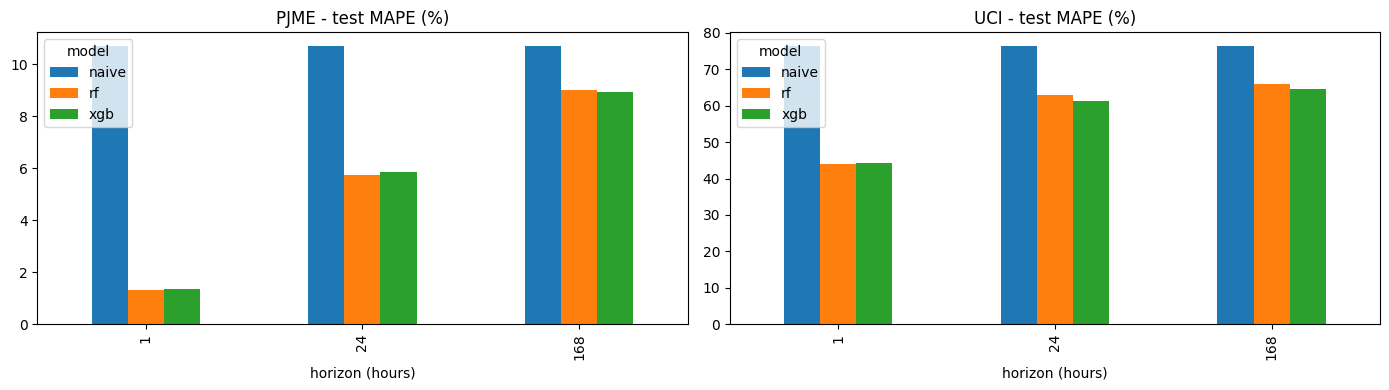

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, name in zip(ax, ["pjme", "uci"]):
    d = scores_df[scores_df["dataset"] == name].groupby(["horizon", "model"])["mape"].mean().unstack()
    d.plot(kind="bar", ax=a)
    a.set_title(name.upper() + " - test MAPE (%)")
    a.set_xlabel("horizon (hours)")
plt.tight_layout()
plt.savefig("../figures/04_test_mape.png", dpi=150, bbox_inches="tight")
plt.show()

Notes:
- PJME 1h: both models are very accurate (MAPE ~1.3%). Error grows a lot with the horizon (~5.8% at 24h, ~9% at 168h).
- PJME: RF is a bit better at 1h and 24h, XGBoost at 168h - the two are very close everywhere.
- Both models beat the seasonal naive forecast (10.7%) at every horizon.
- UCI is much harder: R2 only ~0.58 at 1h and ~0.33 at 168h. XGBoost is a bit better than RF at all horizons.
  MAPE is very high (44-66%) because night values are close to zero (~0.12-0.3 kW), so small errors give
  big percentages - RMSE and MAE are more useful for UCI.
- For UCI 24h and 168h are almost the same - after one day there is little extra information from recent hours (matches the low ACF in notebook 03).
- Compared to tuning at every horizon with all PJME train data (first version), the 1h PJME error is higher
  (XGBoost RMSE 549 vs 322 MW) because the settings are tuned at 24h. The other horizons and UCI change very little.
- Std over seeds is small (PJME < 0.03% MAPE, UCI up to ~0.1%).


##### Feature importance (24h models)

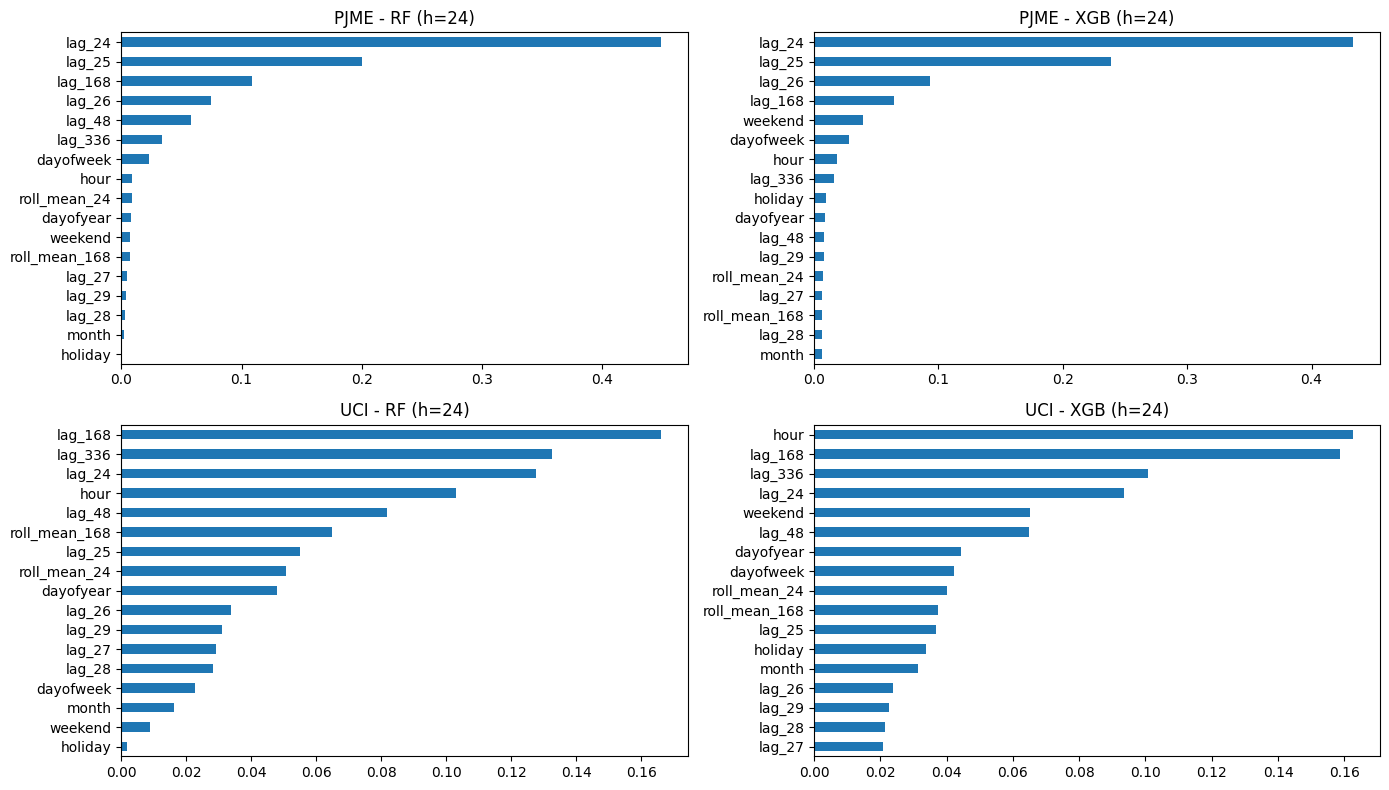

In [11]:
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
for i, name in enumerate(["pjme", "uci"]):
    m = models_24[name]
    for j, model in enumerate(["rf", "xgb"]):
        imp = pd.Series(m[model].feature_importances_, index=m["columns"]).sort_values()
        imp.plot(kind="barh", ax=ax[i, j])
        ax[i, j].set_title(f"{name.upper()} - {model.upper()} (h=24)")
plt.tight_layout()
plt.savefig("../figures/04_feature_importance_24h.png", dpi=150, bbox_inches="tight")
plt.show()

##### Forecast vs actual - one test week, 24h ahead

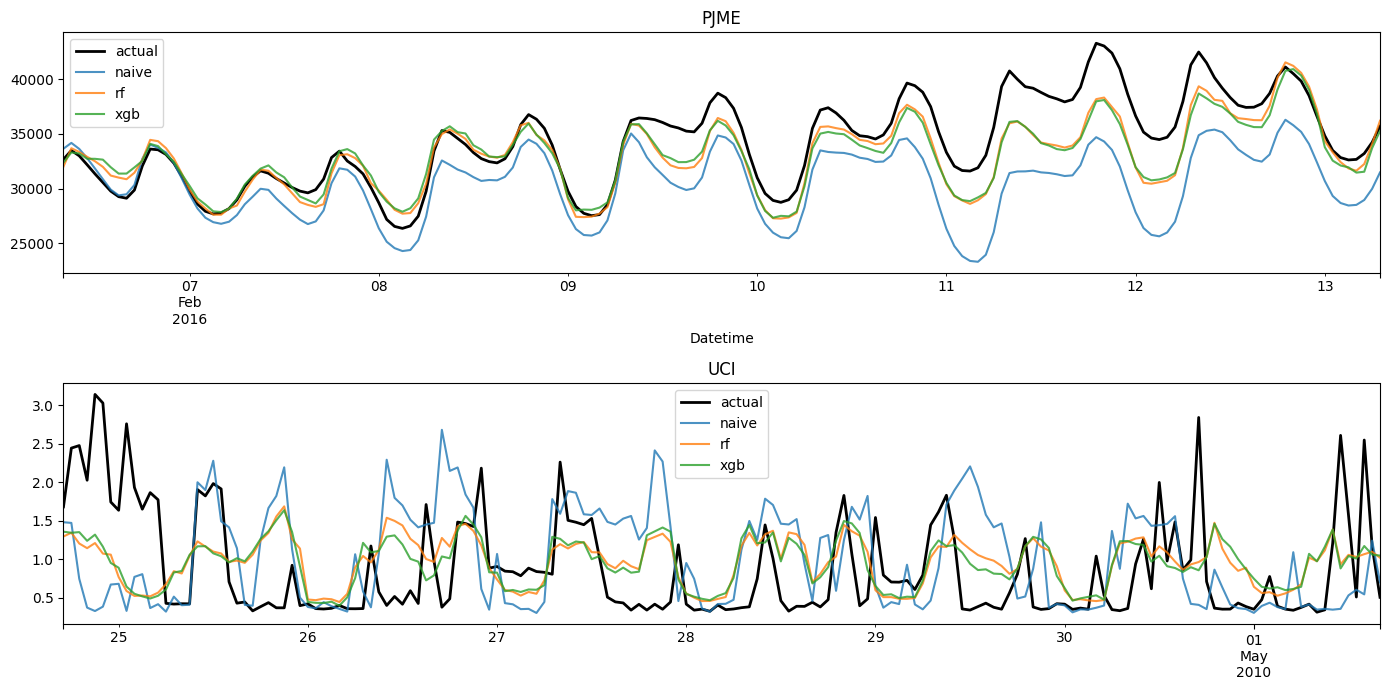

In [12]:
fig, ax = plt.subplots(2, 1, figsize=(14, 7))
for a, name in zip(ax, ["pjme", "uci"]):
    week = slice(None, 24 * 7)
    for model in ["naive", "rf", "xgb"]:
        p = pd.read_parquet(f"../results/predictions/{name}_{model}_h24.parquet")
        if model == "naive":
            p["actual"].iloc[week].plot(ax=a, color="black", lw=2, label="actual")
        p["seed_0"].iloc[week].plot(ax=a, label=model, alpha=0.8)
    a.set_title(name.upper())
    a.legend()
plt.tight_layout()
plt.savefig("../figures/04_forecast_week_24h.png", dpi=150, bbox_inches="tight")
plt.show()